# Langevin em potencial serra suavizado por uma gaussiana

Este experimento usa `Fourie_atenuacao_da_serra` de `utils_coisa/potencial_e_forca.py`. A atenuação `alpha_gaussiana` multiplica cada modo de Fourier pelo fator da gaussiana periódica, equivalente à convolução periódica do potencial com esse núcleo.

A classe de Langevin do projeto recebe `vderivada = dV/dx` e atualiza `x` com `-vderivada`. Como o módulo fornece a força $F=-dV/dx$, definimos `vderivada = -F`; assim, o drift é `funcao_resposta(t) * F(x,t)`. A resposta é periódica: o potencial fica ligado por `tau_resposta` e desligado por mais `tau_resposta`.

In [35]:
from functools import partial
import numpy as np
import matplotlib.pyplot as plt

from utils_coisa.solver import langevin
from utils_coisa.potencial_e_forca import (
    Fourie_atenuacao_da_serra,
    alpha_gaussiana,
)

## Potencial e força

`a` e `b=L-a` definem os comprimentos dos trechos da serra. `sigma` é o desvio padrão da gaussiana periódica; `N_modos` limita a série nos gráficos e na simulação.

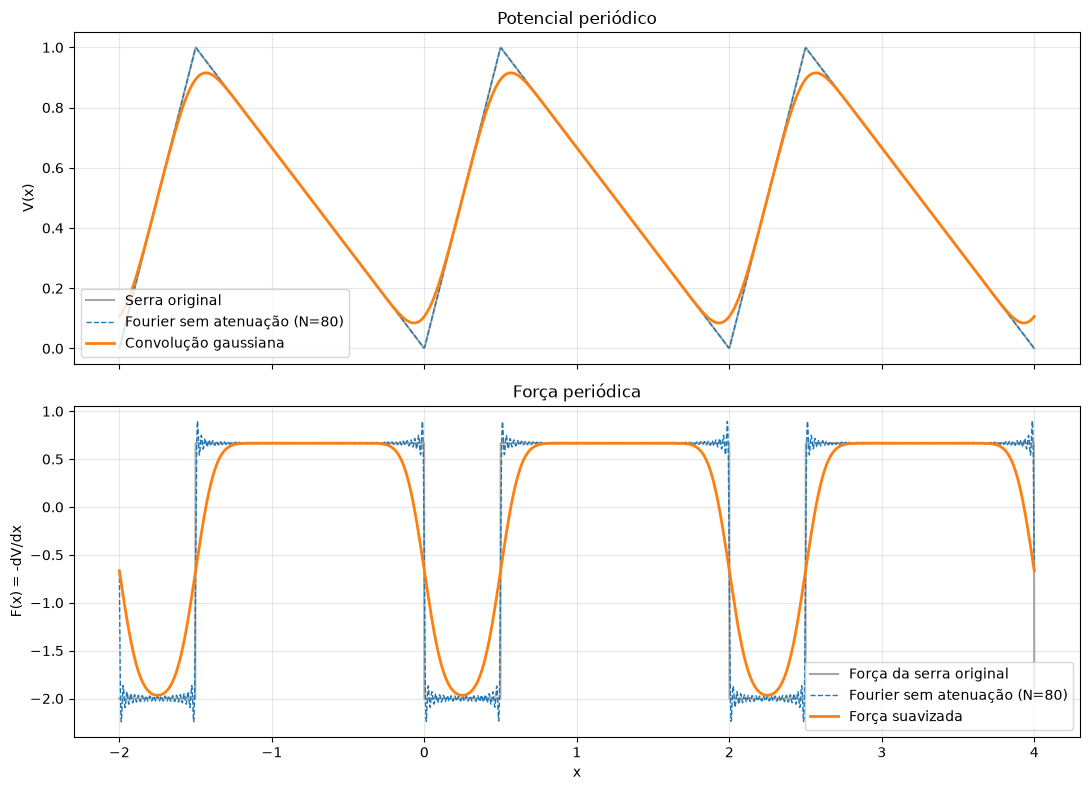

In [36]:
V_0 = 1.0
a = 1.5
L = 2.0
b = L - a
sigma = .1
N_modos = 80

alpha = partial(alpha_gaussiana, sigma=sigma, L=L)
serra = Fourie_atenuacao_da_serra(alpha=alpha, a=a, L=L, V_0=V_0)

x_plot = np.linspace(-L, 2 * L, 2400)
V_suavizado = serra.V_fourier(
    x_plot, parada="N_stop", N_stop=N_modos, atenuado=True
)
F_suavizada = serra.forca_fourrier(
    x_plot, parada="N_stop", N_stop=N_modos, atenuado=True
)
V_sem_atenuacao = serra.V_fourier(
    x_plot, parada="N_stop", N_stop=N_modos, atenuado=False
)
F_sem_atenuacao = serra.forca_fourrier(
    x_plot, parada="N_stop", N_stop=N_modos, atenuado=False
)

fig, (ax_v, ax_f) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
ax_v.plot(x_plot, serra.V_original(x_plot), color="0.65", lw=1.5, label="Serra original")
ax_v.plot(x_plot, V_sem_atenuacao, ls="--", lw=1, label=f"Fourier sem atenuação (N={N_modos})")
ax_v.plot(x_plot, V_suavizado, lw=2, label="Convolução gaussiana")
ax_v.set_ylabel("V(x)")
ax_v.set_title("Potencial periódico")
ax_v.grid(alpha=0.3)
ax_v.legend()

ax_f.plot(x_plot, serra.forca_orginial(x_plot), color="0.65", lw=1.5, label="Força da serra original")
ax_f.plot(x_plot, F_sem_atenuacao, ls="--", lw=1, label=f"Fourier sem atenuação (N={N_modos})")
ax_f.plot(x_plot, F_suavizada, lw=2, label="Força suavizada")
ax_f.set_xlabel("x")
ax_f.set_ylabel("F(x) = -dV/dx")
ax_f.set_title("Força periódica")
ax_f.grid(alpha=0.3)
ax_f.legend()
plt.tight_layout()
plt.show()

## Resposta temporal e integração de Langevin

A resposta alterna entre 1 (potencial ligado) por `tau_resposta` e 0 (potencial desligado) pelo mesmo intervalo. A integração de Euler–Maruyama é $x_{i+1}=x_i-v'(x_i)R(t_i)\,dt+g\sqrt{dt}\,\eta_i$, onde $\eta_i$ é normal padrão e $v'(x)=-F(x)$.

In [ ]:
def funcao_resposta(t, tau_resposta):
    """Começa desligada e alterna ligada/desligada por intervalos iguais."""
    fase = np.mod(t, 2 * tau_resposta)
    if isinstance(fase, np.ndarray):
        return (fase >= tau_resposta).astype(float)
    return float(fase >= tau_resposta)

dt = 0.01
tempo_total = 100.0
tau_resposta = .5
g = 0.7  # amplitude do ruído; dW tem variância dt
n_particulas = 2000
x0 = 0.0

n_passos = int(tempo_total / dt)

x_grade_forca = np.linspace(0.0, L, 8193)
forca_grade = serra.forca_fourrier(
    x_grade_forca, parada="N_stop", N_stop=N_modos, atenuado=True
)

def forca(x):
    # Interpolação periódica da força de Fourier previamente calculada.
    return np.interp(np.mod(x, L), x_grade_forca, forca_grade)

def vderivada(x):
    # O solver recebe dV/dx; a função forca retorna F=-dV/dx.
    return -forca(x)

def resposta_passo(n):
    return funcao_resposta(n * dt, tau_resposta)

dinamica = langevin(
    dt=dt,
    tau_resposta=tau_resposta,
    g=g,
    N_pontos=n_particulas,
    vderivada=vderivada,
    funcao_resposta=resposta_passo,
    rng=None,
)
tempos, media_t, variancia_t = dinamica.resolver_ate_n_estatisticas(
    N=n_passos, x0=x0
)
tempos_resposta = dt * np.arange(n_passos)
resposta = funcao_resposta(tempos_resposta, tau_resposta)
print(f"Passos: {n_passos}; partículas: {n_particulas}; período da resposta: {2*tau_resposta:g}")

Passos: 10000; partículas: 2000; período da resposta: 1


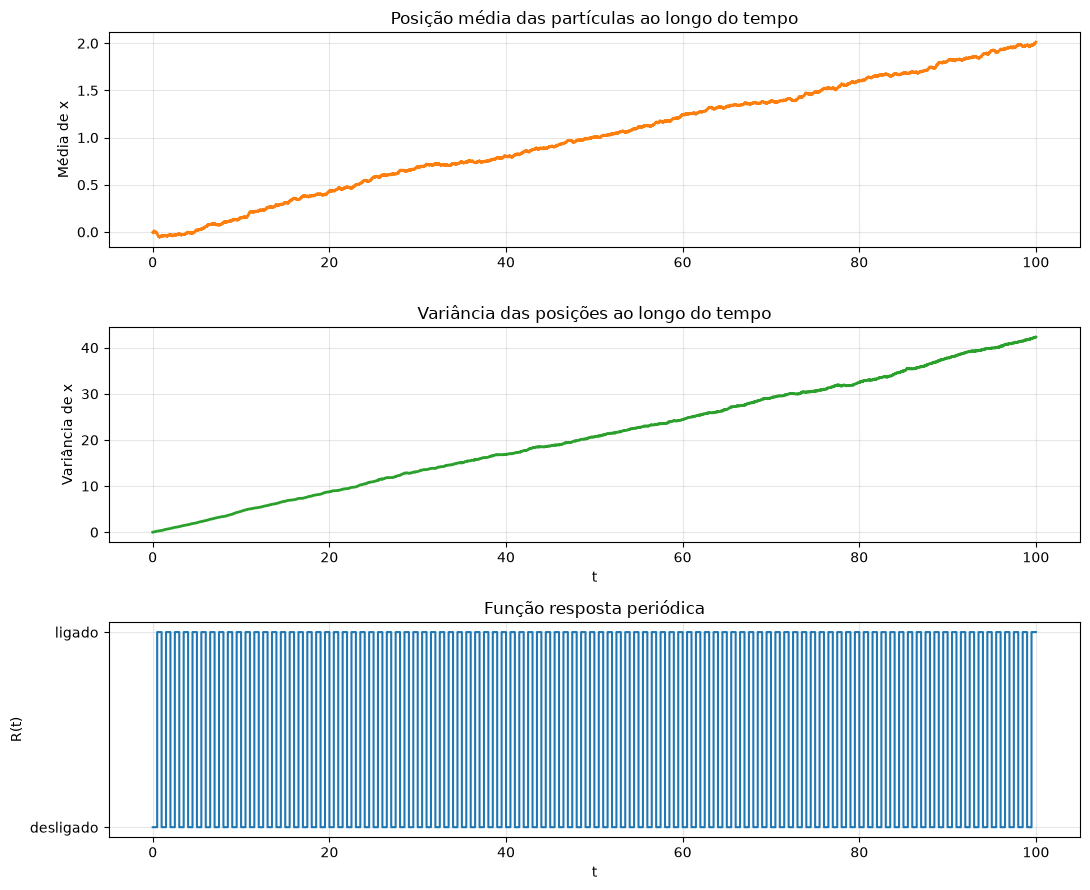

Velocidade média desde o início: 0.0201276


In [38]:
fig, (ax_media, ax_var, ax_resp) = plt.subplots(3, 1, figsize=(11, 9))

ax_media.plot(tempos, media_t, lw=2, color="tab:orange")
ax_media.set_ylabel("Média de x")
ax_media.set_title("Posição média das partículas ao longo do tempo")
ax_media.grid(alpha=0.3)

ax_var.plot(tempos, variancia_t, lw=2, color="tab:green")
ax_var.set_xlabel("t")
ax_var.set_ylabel("Variância de x")
ax_var.set_title("Variância das posições ao longo do tempo")
ax_var.grid(alpha=0.3)

ax_resp.step(tempos_resposta, resposta, where="post")
ax_resp.set_xlabel("t")
ax_resp.set_ylabel("R(t)")
ax_resp.set_yticks([0, 1], labels=["desligado", "ligado"])
ax_resp.set_title("Função resposta periódica")
ax_resp.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Velocidade média desde o início: {media_t[-1] / tempos[-1]:.6g}")

## Velocidade de drift em função de tau_resposta

A varredura também usa a classe langevin de utils_coisa/solver.py. Para cada tau, a função descarta um número configurável de ciclos e ajusta uma reta à posição média retornada por resolver_ate_n_estatisticas durante a janela de medida. A inclinação estima a velocidade média de drift. O passo temporal é ajustado levemente para que cada intervalo de chaveamento contenha um número inteiro de passos.

In [ ]:
def testar_drift(
    taus_resposta,
    dt=0.005,
    n_particulas=1000,
    n_ciclos_transiente=20,
    n_ciclos_medida=20,
    g_ruido=None,
    x0=0.0,
    seed=None,
    plotar=True,
):
    """Compara velocidades de drift usando o solver de Langevin do projeto."""
    taus = np.asarray(taus_resposta, dtype=float)
    if taus.ndim != 1 or taus.size == 0 or np.any(~np.isfinite(taus)) or np.any(taus <= 0):
        raise ValueError("taus_resposta deve ser uma sequência não vazia de valores positivos.")
    if dt <= 0 or n_particulas < 2 or n_ciclos_transiente < 0 or n_ciclos_medida < 1:
        raise ValueError("dt deve ser positivo, n_particulas >= 2 e os ciclos válidos.")

    taus = np.sort(taus)
    amplitude_ruido = g if g_ruido is None else g_ruido
    sementes = np.random.SeedSequence(seed).spawn(len(taus))
    velocidades = np.empty(len(taus))

    for j, tau in enumerate(taus):
        passos_por_intervalo = max(1, int(round(tau / dt)))
        dt_sim = tau / passos_por_intervalo
        n_transiente = 2 * n_ciclos_transiente * passos_por_intervalo
        n_medida = 2 * n_ciclos_medida * passos_por_intervalo
        n_total = n_transiente + n_medida

        def resposta_passo(n, passos=passos_por_intervalo):
            # Primeiro intervalo desligado; depois alterna a cada tau.
            return float((n // passos) % 2 == 1)

        simulador = langevin(
            dt=dt_sim,
            tau_resposta=tau,
            g=amplitude_ruido,
            N_pontos=n_particulas,
            vderivada=vderivada,
            funcao_resposta=resposta_passo,
            rng=np.random.default_rng(sementes[j]),
        )
        tempos, media, _ = simulador.resolver_ate_n_estatisticas(
            N=n_total, x0=x0
        )

        t_inicio_medida = n_transiente * dt_sim
        t_fim_medida = n_total * dt_sim
        janela = (tempos > t_inicio_medida) & (tempos <= t_fim_medida)
        velocidades[j] = np.polyfit(tempos[janela], media[janela], deg=1)[0]

    resultados = {
        "tau_resposta": taus,
        "velocidade": velocidades,
    }

    if plotar:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(taus, velocidades, "o-")
        ax.axhline(0, color="0.4", lw=1, ls="--")
        ax.set_xlabel(r"$\tau_{\mathrm{resposta}}$")
        ax.set_ylabel("Velocidade média de drift")
        ax.set_title(f"Velocidade de drift versus tempo de chaveamento, g = {amplitude_ruido}")
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    return resultados


taus_teste = [0.05, 0.1, 0.2, 0.5, 1.0, 2.0]
resultado_drift = testar_drift(taus_teste, g_ruido=2)
resultado_drift